# 03 · Superresolución 14×14 y 7×7 → 28×28 (nivel básico)

**Objetivo:** entrenar autoencoders que reciben un dígito de MNIST **reducido** a n×n y devuelven la imagen original de 28×28.

- Resoluciones de entrada: **n = 14** y **n = 7**.
- Reducción: `v2.functional.resize(imagen, [n, n], antialias=True)`, lote a lote.
- Entrada = imagen pequeña, objetivo = imagen original de 28×28.
- Modelo principal: **convolucional** (el mejor en `01_ruido_basico.ipynb`), con el encoder adaptado a la entrada pequeña y el decoder de clase. Lo comparamos con un **denso** para justificar la elección.
- Mismos hiperparámetros para todos (MSE, Adam lr=0.001, batch 64, 10 epochs) y misma semilla.
- Referencia sin aprendizaje: ampliar la imagen pequeña a 28×28 con interpolación bilineal.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets
from torchvision.transforms import v2
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo activo: {device}")

Dispositivo activo: cpu


In [2]:
# Transformación limpia: a Tensor y escalado [0.0, 1.0]
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

## Reducir la resolución

In [3]:
def reducir(images, n):
    # Reducimos el lote a n×n (antialias suaviza antes de submuestrear, como al encoger una foto)
    return v2.functional.resize(images, [n, n], antialias=True)

## Autoencoders de superresolución

- **Convolucional:** como la entrada ya es pequeña, las convoluciones del encoder usan `stride=1` (mantienen el tamaño n×n) y la capa lineal pasa de 32·n·n a 64. El decoder es el de clase (7 → 14 → 28).
- **Denso:** el de clase cambiando solo la primera capa (n·n → 256); el decoder llega hasta 784 píxeles.

In [4]:
class AutoencoderSuperresCNN(nn.Module):
    def __init__(self, n):
        super().__init__()

        # --- COMPONENTES DEL ENCODER ---
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=1, padding=1) # N, 1, n, n -> N, 16, n, n
        self.relu1 = nn.ReLU()

        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1) # N, 16, n, n -> N, 32, n, n
        self.relu2 = nn.ReLU()

        self.aplanar = nn.Flatten()
        self.fc_encoder = nn.Linear(in_features=32 * n * n, out_features=64)

        # --- COMPONENTES DEL DECODER (el de clase, sin cambios) ---
        self.fc_decoder = nn.Linear(in_features=64, out_features=32 * 7 * 7)
        self.relu3 = nn.ReLU()

        self.desaplanar = nn.Unflatten(dim=1, unflattened_size=(32, 7, 7))

        self.convT1 = nn.ConvTranspose2d(in_channels=32, out_channels=16, kernel_size=3, stride=2, padding=1, output_padding=1) # N, 32, 7, 7 -> N, 16, 14, 14
        self.relu4 = nn.ReLU()

        self.convT2 = nn.ConvTranspose2d(in_channels=16, out_channels=1, kernel_size=3, stride=2, padding=1, output_padding=1) # N, 16, 14, 14 -> N, 1, 28, 28
        self.sigmoid = nn.Sigmoid()

    def encode(self, x):
        x = self.conv1(x)
        x = self.relu1(x)

        x = self.conv2(x)
        x = self.relu2(x)

        x = self.aplanar(x)
        z = self.fc_encoder(x)
        return z

    def decode(self, z):
        x = self.fc_decoder(z)
        x = self.relu3(x)

        x = self.desaplanar(x)

        x = self.convT1(x)
        x = self.relu4(x)

        x = self.convT2(x)
        x = self.sigmoid(x)
        return x

    def forward(self, x):
        z = self.encode(x)
        x_recon = self.decode(z)
        return x_recon

In [5]:
class AutoencoderSuperresDenso(nn.Module):
    def __init__(self, n):
        super().__init__()

        # --- COMPONENTES DEL ENCODER ---
        # A diferencia de la CNN, aplanamos la imagen inmediatamente al entrar
        self.aplanar = nn.Flatten()

        # Capas densas (Fully Connected) de compresión progresiva
        self.fc_encoder1 = nn.Linear(in_features=n * n, out_features=256)
        self.relu1 = nn.ReLU()

        self.fc_encoder2 = nn.Linear(in_features=256, out_features=128)
        self.relu2 = nn.ReLU()

        # Cuello de botella: proyecta al espacio latente de 64D
        self.fc_encoder3 = nn.Linear(in_features=128, out_features=64)

        # --- COMPONENTES DEL DECODER ---
        # Capas densas de expansión progresiva
        self.fc_decoder1 = nn.Linear(in_features=64, out_features=128)
        self.relu3 = nn.ReLU()

        self.fc_decoder2 = nn.Linear(in_features=128, out_features=256)
        self.relu4 = nn.ReLU()

        # Proyecta de nuevo a la cantidad total de píxeles originales (784)
        self.fc_decoder3 = nn.Linear(in_features=256, out_features=28 * 28)
        self.sigmoid = nn.Sigmoid()

        # Restauramos la topología 2D para que la salida vuelva a ser una imagen
        self.desaplanar = nn.Unflatten(dim=1, unflattened_size=(1, 28, 28))

    def encode(self, x):
        """Transforma la imagen pequeña en un vector latente de 64D."""
        x = self.aplanar(x)     # [batch, 1, n, n] -> [batch, n·n]

        x = self.fc_encoder1(x)         # [batch, n·n] -> [batch, 256]
        x = self.relu1(x)

        x = self.fc_encoder2(x)         # [batch, 256] -> [batch, 128]
        x = self.relu2(x)

        z = self.fc_encoder3(x)  # [batch, 128] -> [batch, 64]
        return z

    def decode(self, z):
        """Reconstruye los píxeles a partir del vector latente."""
        x = self.fc_decoder1(z) # [batch, 64] -> [batch, 128]
        x = self.relu3(x)

        x = self.fc_decoder2(x) # [batch, 128] -> [batch, 256]
        x = self.relu4(x)

        x = self.fc_decoder3(x) # [batch, 256] -> [batch, 784]
        x = self.sigmoid(x)     # Escala píxeles al rango [0.0, 1.0]

        x = self.desaplanar(x)  # [batch, 784] -> [batch, 1, 28, 28]
        return x

    def forward(self, x):
        """Flujo orquestado: imagen pequeña -> vector latente -> imagen de 28×28."""
        z = self.encode(x)
        x_recon = self.decode(z)
        return x_recon

## Entrenamiento, evaluación y visualización

In [6]:
def entrenar(modelo, n, epochs=10):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(modelo.parameters(), lr=0.001)

    for epoch in range(epochs):
        modelo.train()
        perdida_total = 0.0

        for images, _ in train_loader:
            images = images.to(device)
            # Reducimos el lote a n×n
            images_peq = reducir(images, n)

            optimizer.zero_grad()
            # Entrada: imagen pequeña
            reconstruccion = modelo(images_peq)
            # Objetivo: imagen original de 28×28
            loss = criterion(reconstruccion, images)
            loss.backward()
            optimizer.step()

            perdida_total += loss.item()

        perdida_media = perdida_total / len(train_loader)
        print(f"n={n} | Epoch {epoch+1}/{epochs} | Loss (MSE): {perdida_media:.4f}")

In [7]:
def evaluar(modelo, n):
    # Devuelve el MSE medio en test de la imagen ampliada con interpolación bilineal (referencia sin
    # aprendizaje) y de la reconstruida por el autoencoder (ambas frente a la original)
    criterion = nn.MSELoss()
    modelo.eval()
    mse_interp, mse_recon = 0.0, 0.0

    with torch.no_grad():
        for images, _ in test_loader:
            images = images.to(device)
            images_peq = reducir(images, n)
            images_interp = v2.functional.resize(images_peq, [28, 28])  # bilineal por defecto
            reconstruccion = modelo(images_peq)

            mse_interp += criterion(images_interp, images).item()
            mse_recon += criterion(reconstruccion, images).item()

    return mse_interp / len(test_loader), mse_recon / len(test_loader)

In [8]:
def mostrar_resultados(originales, entradas, salidas, titulo, fila2="Con ruido", num_imagenes=10):
    # Matriz de 3 filas: originales, entradas al autoencoder y salidas del autoencoder
    fig, axes = plt.subplots(3, num_imagenes, figsize=(15, 5))

    for i in range(num_imagenes):
        axes[0, i].imshow(originales[i].squeeze(), cmap='gray')
        axes[0, i].set_title("Original")
        axes[0, i].axis('off')

        axes[1, i].imshow(entradas[i].squeeze(), cmap='gray')
        axes[1, i].set_title(fila2)
        axes[1, i].axis('off')

        axes[2, i].imshow(salidas[i].squeeze(), cmap='gray')
        axes[2, i].set_title("Autoencoder")
        axes[2, i].axis('off')

    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


def visualizar_superres(modelo, n, nombre=None, num_imagenes=10):
    modelo.eval()
    images, _ = next(iter(test_loader))
    images = images.to(device)

    images_peq = reducir(images, n)
    with torch.no_grad():
        reconstrucciones = modelo(images_peq)

    # El nombre del modelo en el título distingue la figura del denso de la del convolucional
    titulo = f"Superresolución {n}×{n} → 28×28"
    if nombre:
        titulo = f"{nombre} · {titulo}"
    mostrar_resultados(images.cpu(), images_peq.cpu(), reconstrucciones.cpu(),
                       titulo, fila2=f"Entrada {n}×{n}", num_imagenes=num_imagenes)

## Superresolución 14×14 → 28×28

===== Convolucional 14×14 → 28×28 =====


n=14 | Epoch 1/10 | Loss (MSE): 0.0224


n=14 | Epoch 2/10 | Loss (MSE): 0.0057


n=14 | Epoch 3/10 | Loss (MSE): 0.0042


n=14 | Epoch 4/10 | Loss (MSE): 0.0035


n=14 | Epoch 5/10 | Loss (MSE): 0.0031


... (2 outputs left out)

n=14 | Epoch 8/10 | Loss (MSE): 0.0025


n=14 | Epoch 9/10 | Loss (MSE): 0.0024


n=14 | Epoch 10/10 | Loss (MSE): 0.0023


Test convolucional 14×14: MSE bilineal = 0.0198 | MSE autoencoder = 0.0023 | Parámetros: 512,961


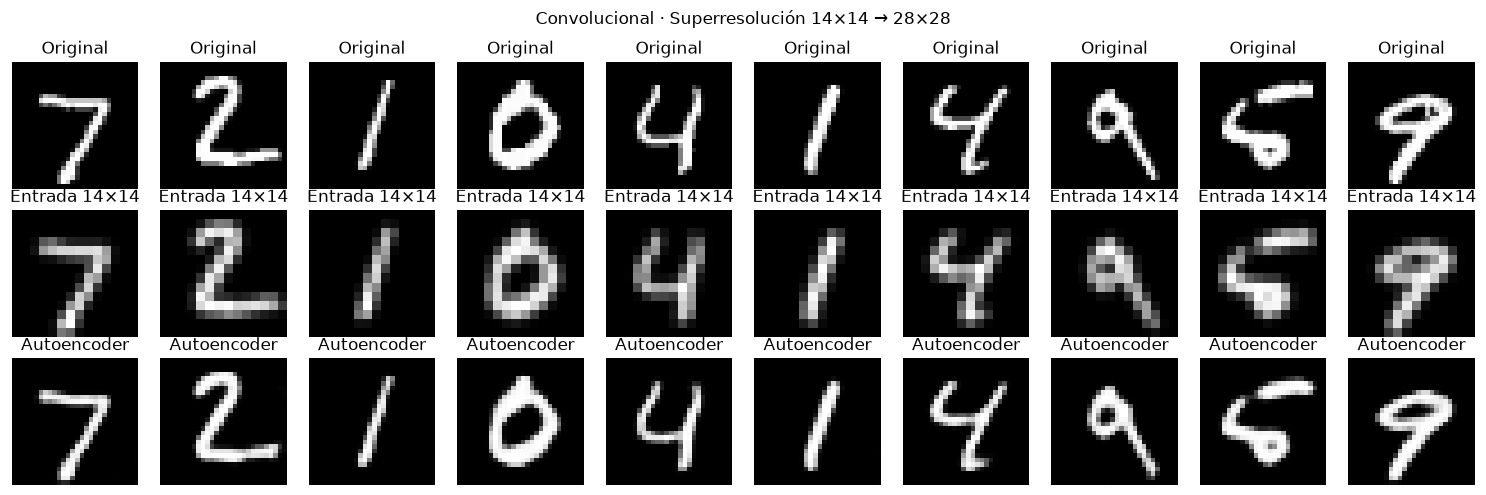

In [9]:
resultados = {}

print("===== Convolucional 14×14 → 28×28 =====")
torch.manual_seed(42)  # misma inicialización para todos los modelos
modelo_cnn_14 = AutoencoderSuperresCNN(n=14).to(device)
entrenar(modelo_cnn_14, n=14)

mse_interp, mse_recon = evaluar(modelo_cnn_14, n=14)
num_params = sum(p.numel() for p in modelo_cnn_14.parameters())
resultados[("Convolucional", 14)] = (mse_interp, mse_recon, num_params)
print(f"Test convolucional 14×14: MSE bilineal = {mse_interp:.4f} | MSE autoencoder = {mse_recon:.4f} | Parámetros: {num_params:,}")

visualizar_superres(modelo_cnn_14, n=14, nombre="Convolucional")

===== Denso 14×14 → 28×28 =====


n=14 | Epoch 1/10 | Loss (MSE): 0.0437


n=14 | Epoch 2/10 | Loss (MSE): 0.0216


n=14 | Epoch 3/10 | Loss (MSE): 0.0167


n=14 | Epoch 4/10 | Loss (MSE): 0.0142


n=14 | Epoch 5/10 | Loss (MSE): 0.0124


... (2 outputs left out)

n=14 | Epoch 8/10 | Loss (MSE): 0.0094


n=14 | Epoch 9/10 | Loss (MSE): 0.0088


n=14 | Epoch 10/10 | Loss (MSE): 0.0084


Test denso 14×14: MSE bilineal = 0.0198 | MSE autoencoder = 0.0082 | Parámetros: 334,416


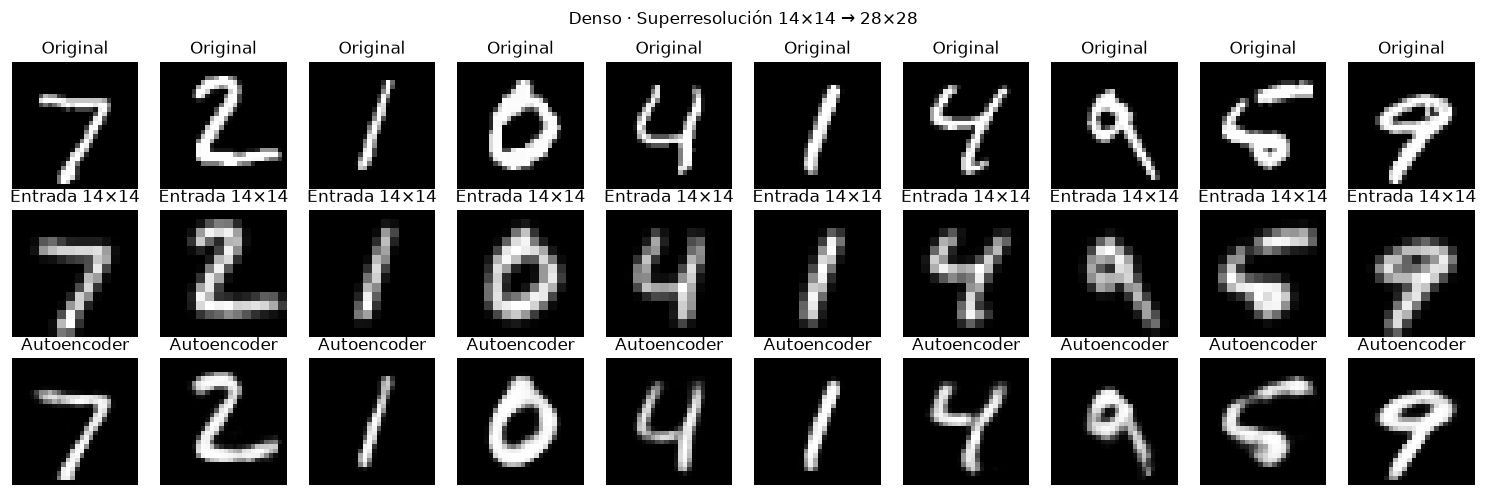

In [10]:
print("===== Denso 14×14 → 28×28 =====")
torch.manual_seed(42)  # misma inicialización para todos los modelos
modelo_denso_14 = AutoencoderSuperresDenso(n=14).to(device)
entrenar(modelo_denso_14, n=14)

mse_interp, mse_recon = evaluar(modelo_denso_14, n=14)
num_params = sum(p.numel() for p in modelo_denso_14.parameters())
resultados[("Denso", 14)] = (mse_interp, mse_recon, num_params)
print(f"Test denso 14×14: MSE bilineal = {mse_interp:.4f} | MSE autoencoder = {mse_recon:.4f} | Parámetros: {num_params:,}")

visualizar_superres(modelo_denso_14, n=14, nombre="Denso")

## Superresolución 7×7 → 28×28

===== Convolucional 7×7 → 28×28 =====


n=7 | Epoch 1/10 | Loss (MSE): 0.0367


n=7 | Epoch 2/10 | Loss (MSE): 0.0123


n=7 | Epoch 3/10 | Loss (MSE): 0.0095


n=7 | Epoch 4/10 | Loss (MSE): 0.0081


n=7 | Epoch 5/10 | Loss (MSE): 0.0073


... (2 outputs left out)

n=7 | Epoch 8/10 | Loss (MSE): 0.0060


n=7 | Epoch 9/10 | Loss (MSE): 0.0058


n=7 | Epoch 10/10 | Loss (MSE): 0.0056


Test convolucional 7×7: MSE bilineal = 0.0452 | MSE autoencoder = 0.0054 | Parámetros: 211,905


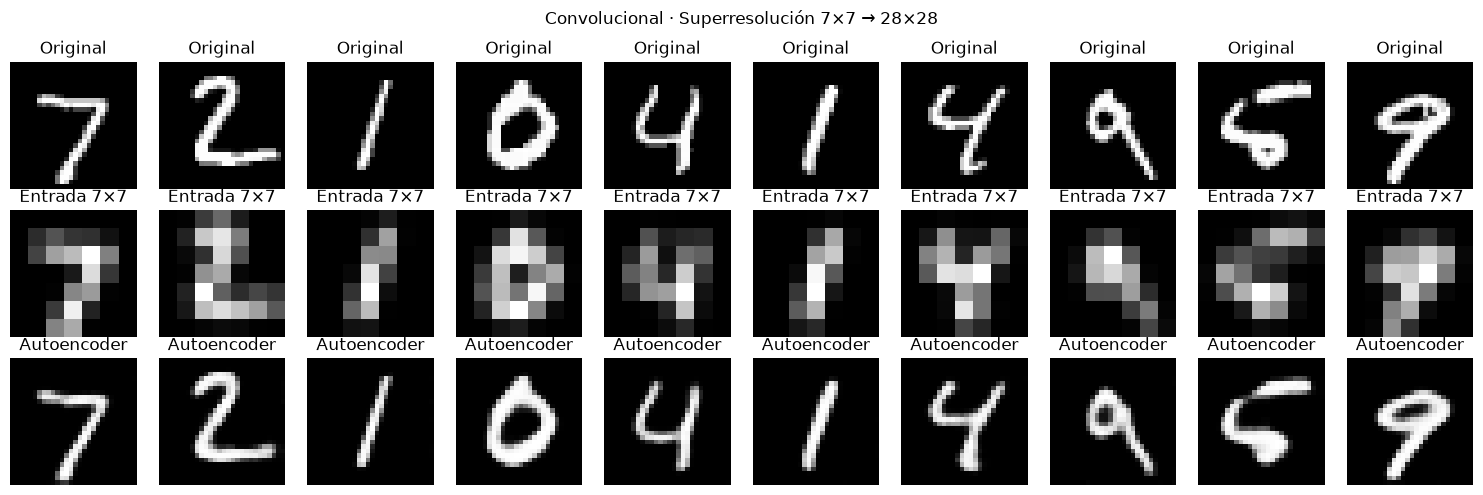

In [11]:
print("===== Convolucional 7×7 → 28×28 =====")
torch.manual_seed(42)  # misma inicialización para todos los modelos
modelo_cnn_7 = AutoencoderSuperresCNN(n=7).to(device)
entrenar(modelo_cnn_7, n=7)

mse_interp, mse_recon = evaluar(modelo_cnn_7, n=7)
num_params = sum(p.numel() for p in modelo_cnn_7.parameters())
resultados[("Convolucional", 7)] = (mse_interp, mse_recon, num_params)
print(f"Test convolucional 7×7: MSE bilineal = {mse_interp:.4f} | MSE autoencoder = {mse_recon:.4f} | Parámetros: {num_params:,}")

visualizar_superres(modelo_cnn_7, n=7, nombre="Convolucional")

===== Denso 7×7 → 28×28 =====


n=7 | Epoch 1/10 | Loss (MSE): 0.0463


n=7 | Epoch 2/10 | Loss (MSE): 0.0247


n=7 | Epoch 3/10 | Loss (MSE): 0.0204


n=7 | Epoch 4/10 | Loss (MSE): 0.0177


n=7 | Epoch 5/10 | Loss (MSE): 0.0157


... (2 outputs left out)

n=7 | Epoch 8/10 | Loss (MSE): 0.0125


n=7 | Epoch 9/10 | Loss (MSE): 0.0118


n=7 | Epoch 10/10 | Loss (MSE): 0.0112


Test denso 7×7: MSE bilineal = 0.0452 | MSE autoencoder = 0.0108 | Parámetros: 296,784


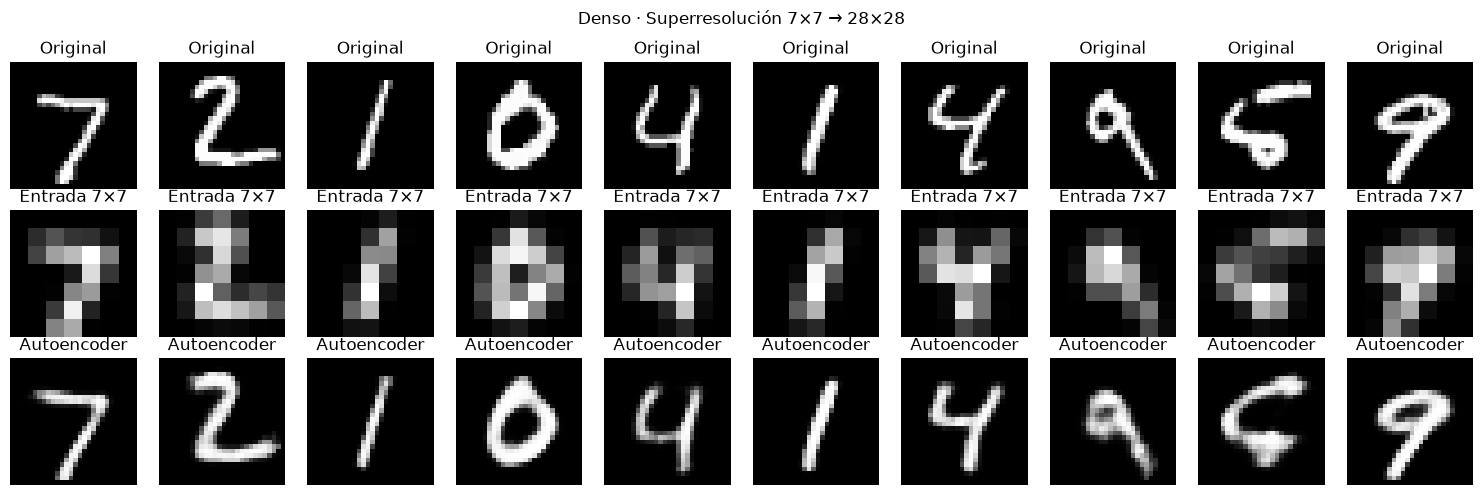

In [12]:
print("===== Denso 7×7 → 28×28 =====")
torch.manual_seed(42)  # misma inicialización para todos los modelos
modelo_denso_7 = AutoencoderSuperresDenso(n=7).to(device)
entrenar(modelo_denso_7, n=7)

mse_interp, mse_recon = evaluar(modelo_denso_7, n=7)
num_params = sum(p.numel() for p in modelo_denso_7.parameters())
resultados[("Denso", 7)] = (mse_interp, mse_recon, num_params)
print(f"Test denso 7×7: MSE bilineal = {mse_interp:.4f} | MSE autoencoder = {mse_recon:.4f} | Parámetros: {num_params:,}")

visualizar_superres(modelo_denso_7, n=7, nombre="Denso")

## Resumen de resultados

In [13]:
# El MSE bilineal solo depende de n, así que es el mismo para el conv y el denso
print(f"{'Modelo':>14} | {'Entrada':>7} | {'MSE bilineal':>12} | {'MSE autoencoder':>16} | {'Parámetros':>10}")
print("-" * 72)
for (nombre, n), (mse_interp, mse_recon, num_params) in resultados.items():
    print(f"{nombre:>14} | {f'{n}×{n}':>7} | {mse_interp:>12.4f} | {mse_recon:>16.4f} | {num_params:>10,}")

for n in (14, 7):
    mejor = min(("Convolucional", "Denso"), key=lambda nombre: resultados[(nombre, n)][1])
    print(f"\nMejor modelo desde {n}×{n}: {mejor}")

        Modelo | Entrada | MSE bilineal |  MSE autoencoder | Parámetros
------------------------------------------------------------------------
 Convolucional |   14×14 |       0.0198 |           0.0023 |    512,961
         Denso |   14×14 |       0.0198 |           0.0082 |    334,416
 Convolucional |     7×7 |       0.0452 |           0.0054 |    211,905
         Denso |     7×7 |       0.0452 |           0.0108 |    296,784

Mejor modelo desde 14×14: Convolucional

Mejor modelo desde 7×7: Convolucional


## Conclusiones

| Modelo | Entrada | MSE bilineal | MSE autoencoder |
|---|---|---|---|
| Convolucional | 14×14 | 0.0198 | **0.0023** |
| Denso | 14×14 | 0.0198 | 0.0082 |
| Convolucional | 7×7 | 0.0452 | **0.0054** |
| Denso | 7×7 | 0.0452 | 0.0108 |

- Los cuatro autoencoders mejoran claramente el reescalado bilineal (la referencia sin aprendizaje): desde 14×14 el error baja de 0.0198 a 0.0023 con el convolucional (unas 8,6 veces menos) y a 0.0082 con el denso; desde 7×7 baja de 0.0452 a 0.0054 y 0.0108.
- **El convolucional es el mejor en los dos tamaños:** tiene un 72 % menos de error que el denso con 14×14 y un 50 % menos con 7×7. Con 14×14 tiene más parámetros que el denso (513 000 frente a 334 000), pero con 7×7 tiene menos (212 000 frente a 297 000) y sigue ganando, así que la ventaja viene de las convoluciones y no del tamaño del modelo. De hecho, el convolucional desde 7×7 (0.0054) es mejor que el denso desde 14×14 (0.0082).
- Reducir la entrada de 14×14 a 7×7 (4 veces menos píxeles) empeora el resultado: el error del convolucional pasa de 0.0023 a 0.0054 (unas 2,3 veces más) y el del denso de 0.0082 a 0.0108.
- En las figuras, el convolucional reconstruye dígitos nítidos incluso desde 7×7, donde a simple vista cuesta reconocerlos; el denso sale más borroso y con 7×7 deforma algunos dígitos (el 9 y el 5 de las últimas columnas).